In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ecom = pd.read_csv("pakistani_ecommerce_dataset.csv")
students = pd.read_csv("student_lifestyle_dataset.csv")

# Exploring the Data Set

In [5]:
ecom.head()

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


In [6]:
ecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           100 non-null    str    
 1   gender            100 non-null    str    
 2   age_group         100 non-null    str    
 3   city              100 non-null    str    
 4   product_category  100 non-null    str    
 5   payment_method    100 non-null    str    
 6   order_value       100 non-null    float64
 7   order_status      100 non-null    str    
dtypes: float64(1), str(7)
memory usage: 11.3 KB


In [7]:
ecom.isnull().sum()

user_id             0
gender              0
age_group           0
city                0
product_category    0
payment_method      0
order_value         0
order_status        0
dtype: int64

# Q1: Most popular product category

In [8]:
ecom["product_category"].value_counts()

product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64

 Answer: Home decor 30

# Q2: Average order value

In [9]:
ecom["order_value"].mean()

np.float64(2832.1480999999994)

 Answer: Rs. 2,832.15.

# Q3: City with the most orders

In [10]:
ecom["city"].value_counts()

city
Karachi       24
Islamabad     21
Rawalpindi    20
Lahore        18
Faisalabad    17
Name: count, dtype: int64

Answer: Karachi (24 orders).

# Q4: Most used payment method

In [11]:
ecom["payment_method"].value_counts()

payment_method
Cash on Delivery    29
JazzCash            27
EasyPaisa           23
Debit Card          21
Name: count, dtype: int64

Answer : Cash on Delivery (29 orders).

# Q5: Bar chart of average order value by city

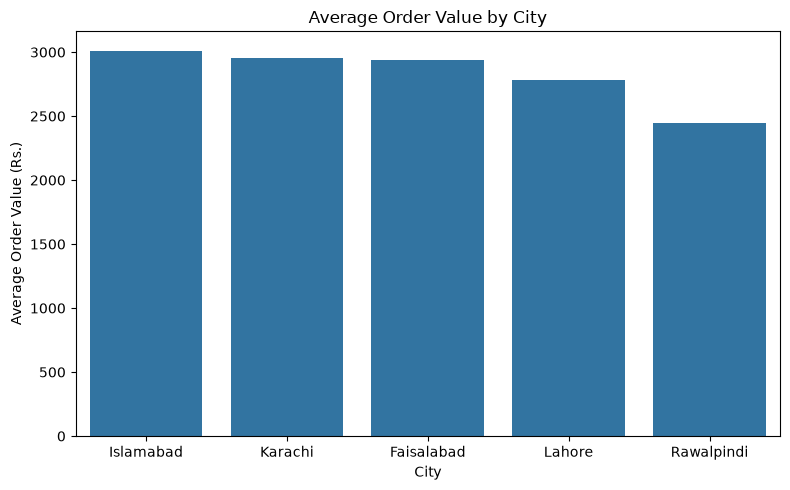

In [12]:
avg_city = ecom.groupby("city")["order_value"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_city.index, y=avg_city.values)
plt.title("Average Order Value by City")
plt.xlabel("City")
plt.ylabel("Average Order Value (Rs.)")
plt.tight_layout()
plt.show()

Interpretation: Islamabad is highest (about Rs. 3,012) and Rawalpindi is lowest (about Rs. 2,447).

In [13]:
students.head()

,student_id,gender,study_hours,sleep_hours,screen_time,internet_usage,daily_transport_cost
0,S001,Female,7.0,7.1,2.7,9.3,102.0
1,S002,Female,4.9,6.9,2.9,1.0,284.0
2,S003,Female,5.9,8.9,5.3,5.2,123.0
3,S004,Female,3.2,4.2,1.8,5.2,73.0
4,S005,Male,1.8,5.0,2.5,6.1,202.0


In [14]:
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            100 non-null    str    
 1   gender                100 non-null    str    
 2   study_hours           100 non-null    float64
 3   sleep_hours           100 non-null    float64
 4   screen_time           100 non-null    float64
 5   internet_usage        100 non-null    float64
 6   daily_transport_cost  100 non-null    float64
dtypes: float64(5), str(2)
memory usage: 6.5 KB


In [15]:
students.isnull().sum()

student_id              0
gender                  0
study_hours             0
sleep_hours             0
screen_time             0
internet_usage          0
daily_transport_cost    0
dtype: int64

**Observation:** The student dataset has 100 rows and 7 columns (student_id, gender, study_hours, sleep_hours, screen_time, internet_usage, daily_transport_cost). There are no missing values. All columns except `student_id` and `gender` are numeric.

# Dataset 2: Student Lifestyle

Q1: Average study hours

In [16]:
students["study_hours"].mean()

np.float64(4.4030000000000005)

Answer: 4.40 Hours.

# Q2: Who sleeps more, males or females?

In [17]:
students.groupby("gender")["sleep_hours"].mean()

gender
Female    6.796154
Male      6.389583
Name: sleep_hours, dtype: float64

Answer: Females sleep more (6.80 hours vs 6.39 hours for males).

# Q3: Relationship between screen time and sleep

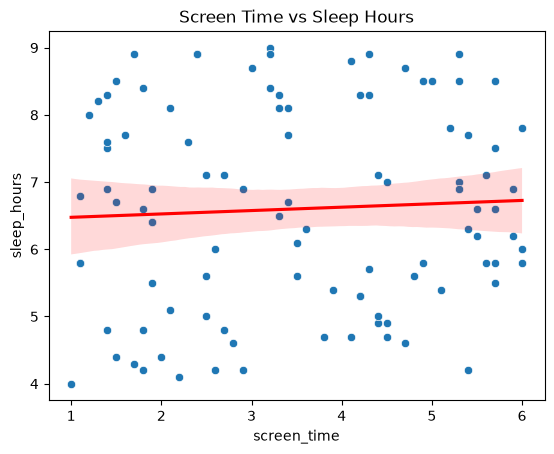

In [18]:
students["screen_time"].corr(students["sleep_hours"])

sns.scatterplot(data=students, x="screen_time", y="sleep_hours")
sns.regplot(data=students, x="screen_time", y="sleep_hours", scatter=False, color="red")
plt.title("Screen Time vs Sleep Hours")
plt.show()

The correlation is 0.05, which is essentially no relationship. This is the question where students lose marks, because they say "yes, there is a relationship". The correct answer is that there is no meaningful relationship. Always include the scatter plot and the correlation value.

# Q4: Histogram of daily transport cost

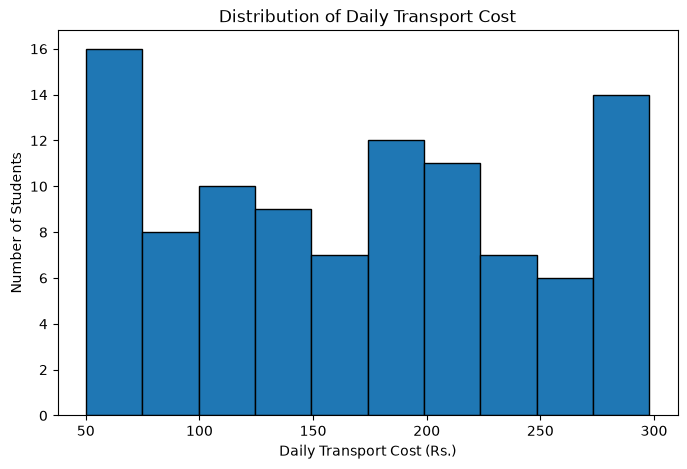

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(students["daily_transport_cost"], bins=10, edgecolor="black")
plt.title("Distribution of Daily Transport Cost")
plt.xlabel("Daily Transport Cost (Rs.)")
plt.ylabel("Number of Students")
plt.show()

Costs range from Rs. 50 to Rs. 298, with a mean of about Rs. 168. The spread is fairly even, not concentrated at one value.

# Q5: Average internet usage by gender

In [20]:
students.groupby("gender")["internet_usage"].mean()

gender
Female    5.321154
Male      6.002083
Name: internet_usage, dtype: float64

Answer: Males use more (6.00 vs 5.32 for females). A small bar chart of this is a cheap bonus